# Pretraining Nepali Transformer Language Model (Model L) on Kaggle
### Course: Language Models and Agents (Monsoon 2026)
**Assignment:** Individual Project — Phase 2: Model Implementation, Pretraining, and Evaluation  
**Language:** Nepali (`ne`) — Low Resource | **Target Parameters:** ~25.27M

This Kaggle notebook pretrains Model L from scratch on the Nepali ~500M token dataset using Kaggle GPU acceleration (T4 x 2 / P100).

In [3]:
# CELL 1 — GPU VERIFICATION & ENVIRONMENT SETUP

!nvidia-smi
!pip install -q sentencepiece pyarrow pandas matplotlib seaborn numpy

import os
import torch

print("\nCUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    raise RuntimeError("GPU not enabled! Go to Settings -> Accelerator -> GPU T4 x 2 or P100")

Sun Sep  6 20:21:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
# CELL 2 — NEPALI PROJECT + DATASET SETUP

import os
import shutil

# 1. Kaggle input paths

CODE_SOURCE = (
    "/kaggle/input/datasets/mohdshahidkaleem/"
    "nepali-code-kaggle/nepali"
)

DATA_SOURCE = None

# Automatically find the dataset containing all 3 parquet files
for root, dirs, files in os.walk("/kaggle/input"):
    if all(f in files for f in ["train.parquet", "val.parquet", "test.parquet"]):
        DATA_SOURCE = root
        break

if DATA_SOURCE is None:
    raise FileNotFoundError(
        "Nepali train/val/test parquet files were not found."
    )

print(" Code source:")
print(CODE_SOURCE)

print("\n Data source:")
print(DATA_SOURCE)


# 2. Copy Nepali project code to /kaggle/working

PROJECT_DIR = "/kaggle/working/nepali"

if not os.path.exists(CODE_SOURCE):
    raise FileNotFoundError(
        f"Nepali code not found:\n{CODE_SOURCE}"
    )

if os.path.exists(PROJECT_DIR):
    shutil.rmtree(PROJECT_DIR)

shutil.copytree(CODE_SOURCE, PROJECT_DIR)

print("\n Nepali project copied to:")
print(PROJECT_DIR)


# 3. Connect train/validation/test datasets

SPLIT_DIR = os.path.join(PROJECT_DIR, "data", "splits")
os.makedirs(SPLIT_DIR, exist_ok=True)

for filename in ["train.parquet", "val.parquet", "test.parquet"]:

    source = os.path.join(DATA_SOURCE, filename)
    target = os.path.join(SPLIT_DIR, filename)

    if not os.path.exists(source):
        raise FileNotFoundError(
            f"Dataset file not found:\n{source}"
        )

    if os.path.lexists(target):
        os.remove(target)

    os.symlink(source, target)

    size_gb = os.path.getsize(source) / (1024**3)

    print(f" {filename} connected ({size_gb:.2f} GB)")


# 4. Verify tokenizer

TOKENIZER = os.path.join(
    PROJECT_DIR,
    "tokenizer",
    "unigram_10k",
    "tokenizer.model"
)

if not os.path.exists(TOKENIZER):
    raise FileNotFoundError(
        f"Nepali tokenizer not found:\n{TOKENIZER}"
    )

print("\n Nepali tokenizer found:")
print(TOKENIZER)


# 5. Verify important project files

required_files = [
    "configs/model_config.json",
    "configs/train_config.json",
    "model/config.py",
    "model/transformer.py",
    "train/dataset.py",
    "train/train.py",
    "eval/evaluate.py",
    "eval/attention_analysis.py",
    "tokenizer/unigram_10k/tokenizer.model",
    "data/splits/train.parquet",
    "data/splits/val.parquet",
    "data/splits/test.parquet",
]

print("\nChecking required files:\n")

for relative_path in required_files:
    path = os.path.join(PROJECT_DIR, relative_path)

    if os.path.exists(path):
        print(" ", relative_path)
    else:
        raise FileNotFoundError(
            f"Missing required file:\n{path}"
        )

# 6. Final setup information

os.chdir("/kaggle/working")

print("\n" + "=" * 60)
print("NEPALI KAGGLE SETUP COMPLETE")
print("=" * 60)

print("Project:", PROJECT_DIR)
print("Dataset:", DATA_SOURCE)
print("Tokenizer:", TOKENIZER)

print("\nTrain:")
print(os.path.realpath(
    os.path.join(SPLIT_DIR, "train.parquet")
))

print("\nValidation:")
print(os.path.realpath(
    os.path.join(SPLIT_DIR, "val.parquet")
))

print("\nTest:")
print(os.path.realpath(
    os.path.join(SPLIT_DIR, "test.parquet")
))

print("\n Ready for Nepali Model L training.")

 Code source:
/kaggle/input/datasets/mohdshahidkaleem/nepali-code-kaggle/nepali

 Data source:
/kaggle/input/datasets/mohdshahidkaleem/nepali-lma-training-data

 Nepali project copied to:
/kaggle/working/nepali
 train.parquet connected (2.33 GB)
 val.parquet connected (0.10 GB)
 test.parquet connected (0.10 GB)

 Nepali tokenizer found:
/kaggle/working/nepali/tokenizer/unigram_10k/tokenizer.model

Checking required files:

  configs/model_config.json
  configs/train_config.json
  model/config.py
  model/transformer.py
  train/dataset.py
  train/train.py
  eval/evaluate.py
  eval/attention_analysis.py
  tokenizer/unigram_10k/tokenizer.model
  data/splits/train.parquet
  data/splits/val.parquet
  data/splits/test.parquet

NEPALI KAGGLE SETUP COMPLETE
Project: /kaggle/working/nepali
Dataset: /kaggle/input/datasets/mohdshahidkaleem/nepali-lma-training-data
Tokenizer: /kaggle/working/nepali/tokenizer/unigram_10k/tokenizer.model

Train:
/kaggle/input/datasets/mohdshahidkaleem/nepali-lma-trai

In [5]:
# CELL 3 — MODEL VERIFICATION

import sys
import torch

sys.path.insert(0, "/kaggle/working")

from nepali.model.config import TransformerConfig
from nepali.model.transformer import TransformerLM

CONFIG_PATH = "/kaggle/working/nepali/configs/model_config.json"

config = TransformerConfig.load_json(CONFIG_PATH)
model = TransformerLM(config)

params = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

tied = (
    model.token_embeddings.weight.data_ptr()
    == model.lm_head.weight.data_ptr()
)

print("Model:", config.model_name)
print(f"Parameters: {params:,} ({params / 1e6:.2f}M)")
print(f"Trainable: {trainable:,} ({trainable / 1e6:.2f}M)")
print(f"Weight tying: {tied}")
print(f"Architecture: {config.n_layers} layers, {config.n_heads} heads")
print(f"d_model: {config.d_model}, d_ff: {config.d_ff}")
print(f"Context: {config.max_seq_len}")
print(f"Vocabulary: {config.vocab_size}")

assert 24e6 <= trainable <= 27e6
assert tied

print("Model verification passed")

Model: Model_L_Nepali_25M
Parameters: 25,330,944 (25.33M)
Trainable: 25,330,944 (25.33M)
Weight tying: True
Architecture: 12 layers, 6 heads
d_model: 384, d_ff: 1536
Context: 512
Vocabulary: 10000
Model verification passed


In [6]:
# CELL 4 — 100-STEP SMOKE TEST

!python /kaggle/working/nepali/train/train.py \
    --config_file /kaggle/working/nepali/configs/model_config.json \
    --train_parquet /kaggle/working/nepali/data/splits/train.parquet \
    --val_parquet /kaggle/working/nepali/data/splits/val.parquet \
    --tokenizer_model /kaggle/working/nepali/tokenizer/unigram_10k/tokenizer.model \
    --output_dir /kaggle/working/nepali_smoke_test \
    --batch_size 32 \
    --max_steps 100 \
    --learning_rate 5e-4 \
    --warmup_steps 20 \
    --eval_interval 50 \
    --eval_batches 20 \
    --save_interval 100 \
    --use_amp \
    --device cuda

PRETRAINING NEPALI TRANSFORMER LM (MODEL L)
Device: cuda
GPU: Tesla T4
CUDA Capability: (7, 5)

Model Parameters Audit:
  total_parameters: 25,330,944
  trainable_parameters: 25,330,944
  embedding_parameters: 4,036,608
  transformer_block_parameters: 21,293,568
  lm_head_parameters: 3,840,000
  weight_tying_applied: 1

Training Settings:
  Batch Size: 32
  Max Seq Len: 512
  Tokens / Step: 16,384
  Max Steps: 100
  Starting Step: 0
  Learning Rate: 0.0005
  Warmup Steps: 20
  Mixed Precision (AMP): True

Step [    50/   100] | Train Loss: 7.9658 | Train PPL: 2880.73 | LR: 3.61e-04 | Tok/s: 27523.4 | Time: 29.8s

---> Running validation at step 50...
---> Step 50 | Val Loss: 7.4125 | Val PPL: 1656.50

[2026-09-06 20:22:23] Saved checkpoint to: /kaggle/working/nepali_smoke_test/checkpoints/checkpoint_latest.pt (step 50)
[2026-09-06 20:22:23] Saved checkpoint to: /kaggle/working/nepali_smoke_test/checkpoints/checkpoint_best.pt (step 50)
Step [   100/   100] | Train Loss: 7.3692 | Train P

In [7]:
# CELL 5 — FULL NEPALI PRETRAINING

!python /kaggle/working/nepali/train/train.py \
    --config_file /kaggle/working/nepali/configs/model_config.json \
    --train_parquet /kaggle/working/nepali/data/splits/train.parquet \
    --val_parquet /kaggle/working/nepali/data/splits/val.parquet \
    --tokenizer_model /kaggle/working/nepali/tokenizer/unigram_10k/tokenizer.model \
    --output_dir /kaggle/working/nepali_checkpoints \
    --batch_size 32 \
    --max_steps 30518 \
    --learning_rate 5e-4 \
    --weight_decay 0.1 \
    --warmup_steps 1000 \
    --grad_clip 1.0 \
    --log_interval 50 \
    --eval_interval 500 \
    --eval_batches 50 \
    --save_interval 2000 \
    --use_amp \
    --device cuda

PRETRAINING NEPALI TRANSFORMER LM (MODEL L)
Device: cuda
GPU: Tesla T4
CUDA Capability: (7, 5)

Model Parameters Audit:
  total_parameters: 25,330,944
  trainable_parameters: 25,330,944
  embedding_parameters: 4,036,608
  transformer_block_parameters: 21,293,568
  lm_head_parameters: 3,840,000
  weight_tying_applied: 1

Training Settings:
  Batch Size: 32
  Max Seq Len: 512
  Tokens / Step: 16,384
  Max Steps: 30,518
  Starting Step: 0
  Learning Rate: 0.0005
  Warmup Steps: 1,000
  Mixed Precision (AMP): True

Step [    50/ 30518] | Train Loss: 8.8441 | Train PPL: 6933.68 | LR: 2.50e-05 | Tok/s: 27033.4 | Time: 30.3s
Step [   100/ 30518] | Train Loss: 8.2569 | Train PPL: 3854.25 | LR: 5.00e-05 | Tok/s: 31319.7 | Time: 26.2s
Step [   150/ 30518] | Train Loss: 7.7490 | Train PPL: 2319.30 | LR: 7.50e-05 | Tok/s: 31858.3 | Time: 25.7s
Step [   200/ 30518] | Train Loss: 7.4893 | Train PPL: 1788.75 | LR: 1.00e-04 | Tok/s: 27228.8 | Time: 30.1s
Step [   250/ 30518] | Train Loss: 7.3177 | Tra

In [8]:
# CELL 6 — RUN EVALUATION SUITE (PPL, BPB, BLEU, chrF++, ROUGE-L)
!python nepali/eval/evaluate.py \
    --checkpoint /kaggle/working/nepali_checkpoints/checkpoints/checkpoint_best.pt \
    --config_file nepali/configs/model_config.json \
    --test_parquet nepali/data/splits/test.parquet \
    --tokenizer_model nepali/tokenizer/unigram_10k/tokenizer.model \
    --output_json nepali/eval/evaluation_results.json

Running Evaluation on device: cuda
Loaded checkpoint from step: 29000 (Vocab: 10000, SeqLen: 512)

[1/2] Computing Intrinsic LM Metrics (Loss, PPL, BPB)...
  CE Loss: 3.8611
  PPL:     47.52
  BPB:     0.4808

[2/2] Evaluating Generation Quality across Temperatures (0.0, 0.5, 1.0, 1.5)...
  [greedy] BLEU-4: 0.70 | chrF++: 11.70 | ROUGE-L: 12.60 | Dist-1: 0.347 | Dist-2: 0.564
  [temp_0.5] BLEU-4: 0.57 | chrF++: 11.32 | ROUGE-L: 10.74 | Dist-1: 0.403 | Dist-2: 0.696
  [temp_1.0] BLEU-4: 0.65 | chrF++: 12.61 | ROUGE-L: 9.14 | Dist-1: 0.486 | Dist-2: 0.875
  [temp_1.5] BLEU-4: 0.00 | chrF++: 14.52 | ROUGE-L: 6.91 | Dist-1: 0.534 | Dist-2: 0.942

Saved evaluation metrics to: nepali/eval/evaluation_results.json


NEPALI TRAINING & VALIDATION LOSS CURVES

Training points   : 611
Validation points : 62


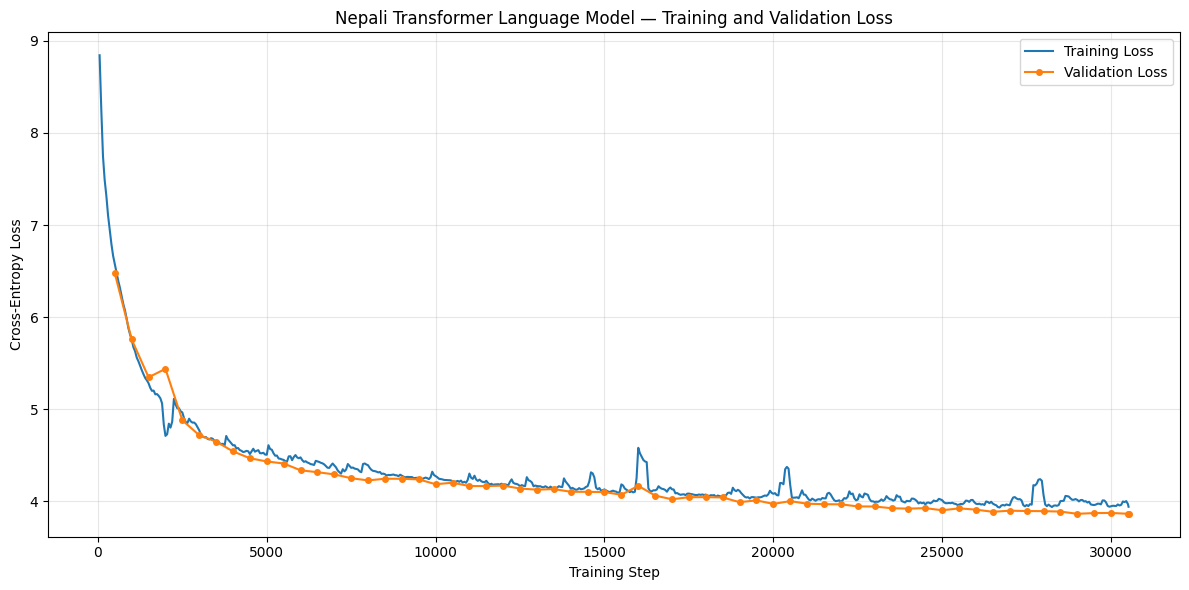


NEPALI LOSS CURVE GENERATED

 Saved to:
/kaggle/working/nepali_checkpoints/nepali_loss_curve.png
File exists: True


In [9]:
# CELL 7 — NEPALI TRAINING & VALIDATION LOSS CURVES

import json
import matplotlib.pyplot as plt
from pathlib import Path

LOG_FILE = Path("/kaggle/working/nepali_checkpoints/train_log.jsonl")
OUTPUT_DIR = Path("/kaggle/working/nepali_checkpoints")

print("=" * 60)
print("NEPALI TRAINING & VALIDATION LOSS CURVES")
print("=" * 60)

# Check training log exists
if not LOG_FILE.exists():
    raise FileNotFoundError(
        f"Training log not found:\n{LOG_FILE}"
    )

# Lists for metrics
train_steps = []
train_losses = []

val_steps = []
val_losses = []

# Read JSONL training log
with open(LOG_FILE, "r", encoding="utf-8") as f:
    for line in f:

        line = line.strip()

        if not line:
            continue

        entry = json.loads(line)

        # Training loss entries
        if "train_loss" in entry and "step" in entry:
            train_steps.append(entry["step"])
            train_losses.append(entry["train_loss"])

        # Validation loss entries
        if "val_loss" in entry and "step" in entry:
            val_steps.append(entry["step"])
            val_losses.append(entry["val_loss"])

print(f"\nTraining points   : {len(train_steps)}")
print(f"Validation points : {len(val_steps)}")

# Create plot
plt.figure(figsize=(12, 6))

if train_steps:
    plt.plot(
        train_steps,
        train_losses,
        linewidth=1.5,
        label="Training Loss"
    )

if val_steps:
    plt.plot(
        val_steps,
        val_losses,
        marker="o",
        markersize=4,
        linewidth=1.5,
        label="Validation Loss"
    )

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Nepali Transformer Language Model — Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save figure
OUTPUT_PATH = OUTPUT_DIR / "nepali_loss_curve.png"

plt.savefig(
    OUTPUT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 60)
print("NEPALI LOSS CURVE GENERATED")
print("=" * 60)

print(f"\n Saved to:\n{OUTPUT_PATH}")
print(f"File exists: {OUTPUT_PATH.exists()}")

Script patched successfully
107: xticklabels=[str(i) for i in range(len(clean_tokens))] if r_idx == num_layers - 1 else False,
108: yticklabels=[str(i) for i in range(len(clean_tokens))] if c_idx == 0 else False,
Analyzing Attention for Nepali Sentence: 'नेपाली भाषा नेपालको राष्ट्रिय भाषा हो।'
Saved attention heatmaps to: nepali/eval/attention/nepali_attention_heatmaps.png
Saved entropy and distance plots to: nepali/eval/attention/nepali_attention_entropy_distance.png
Attention analysis complete.


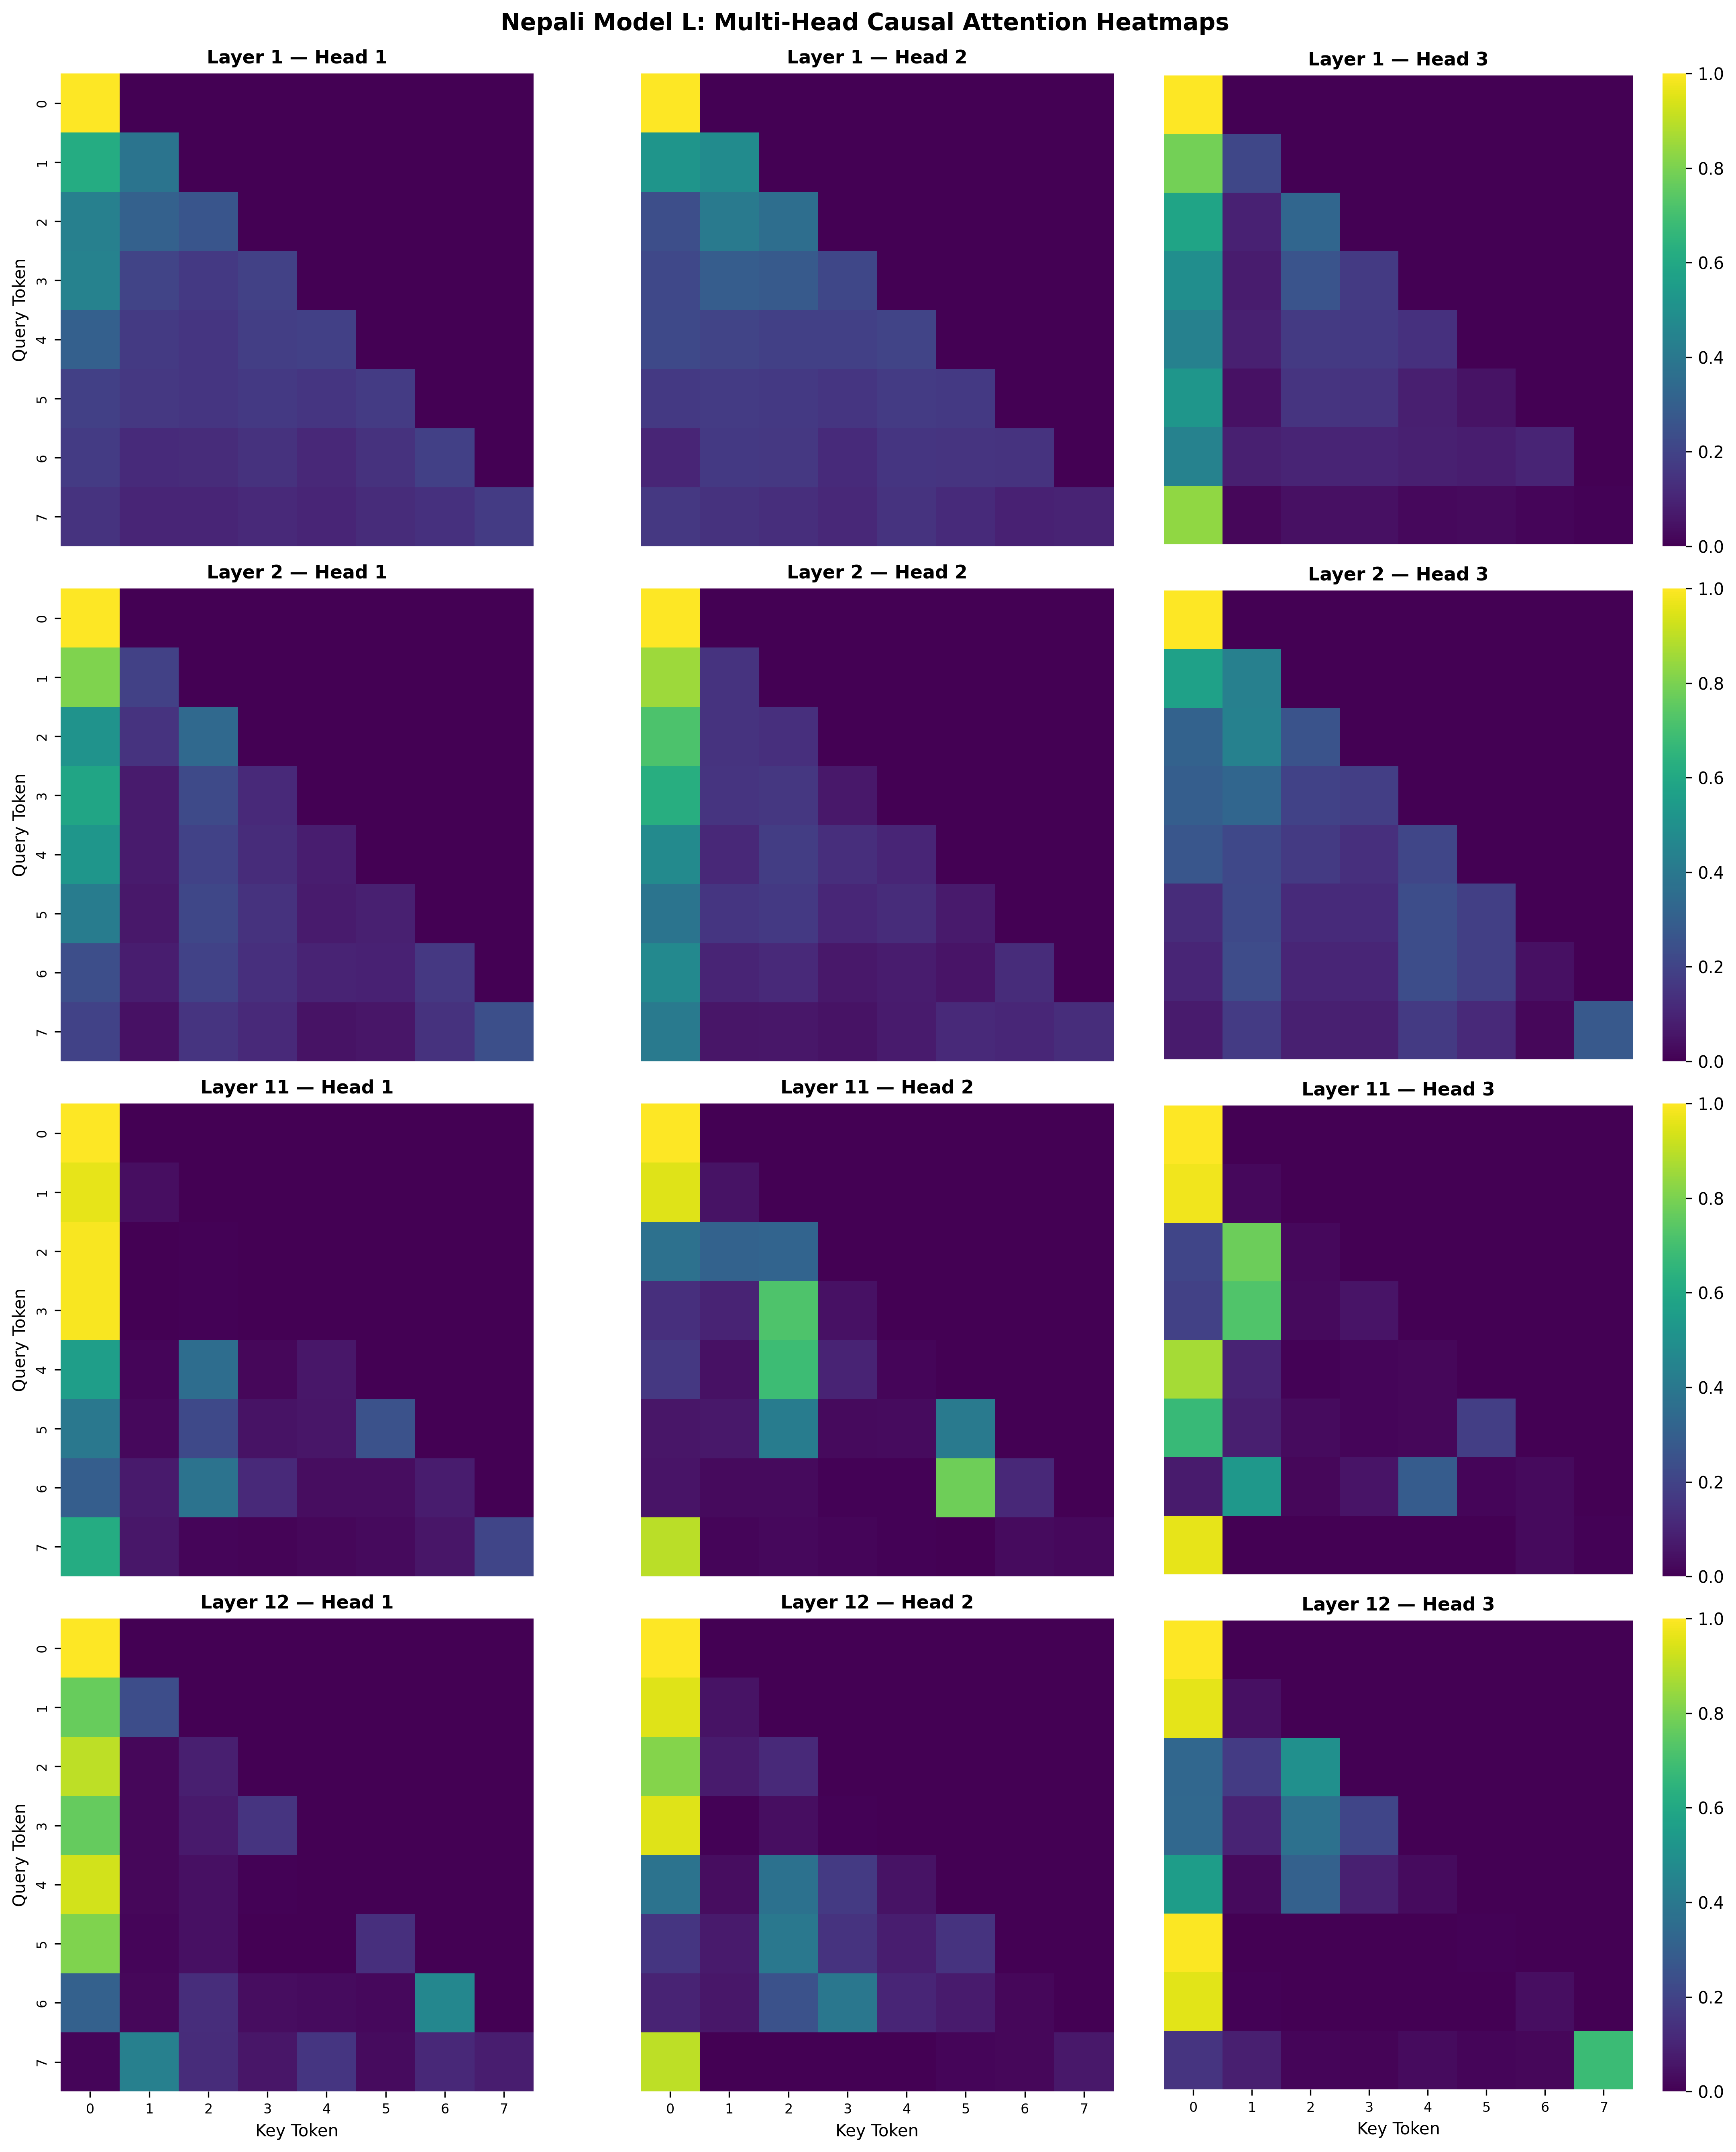

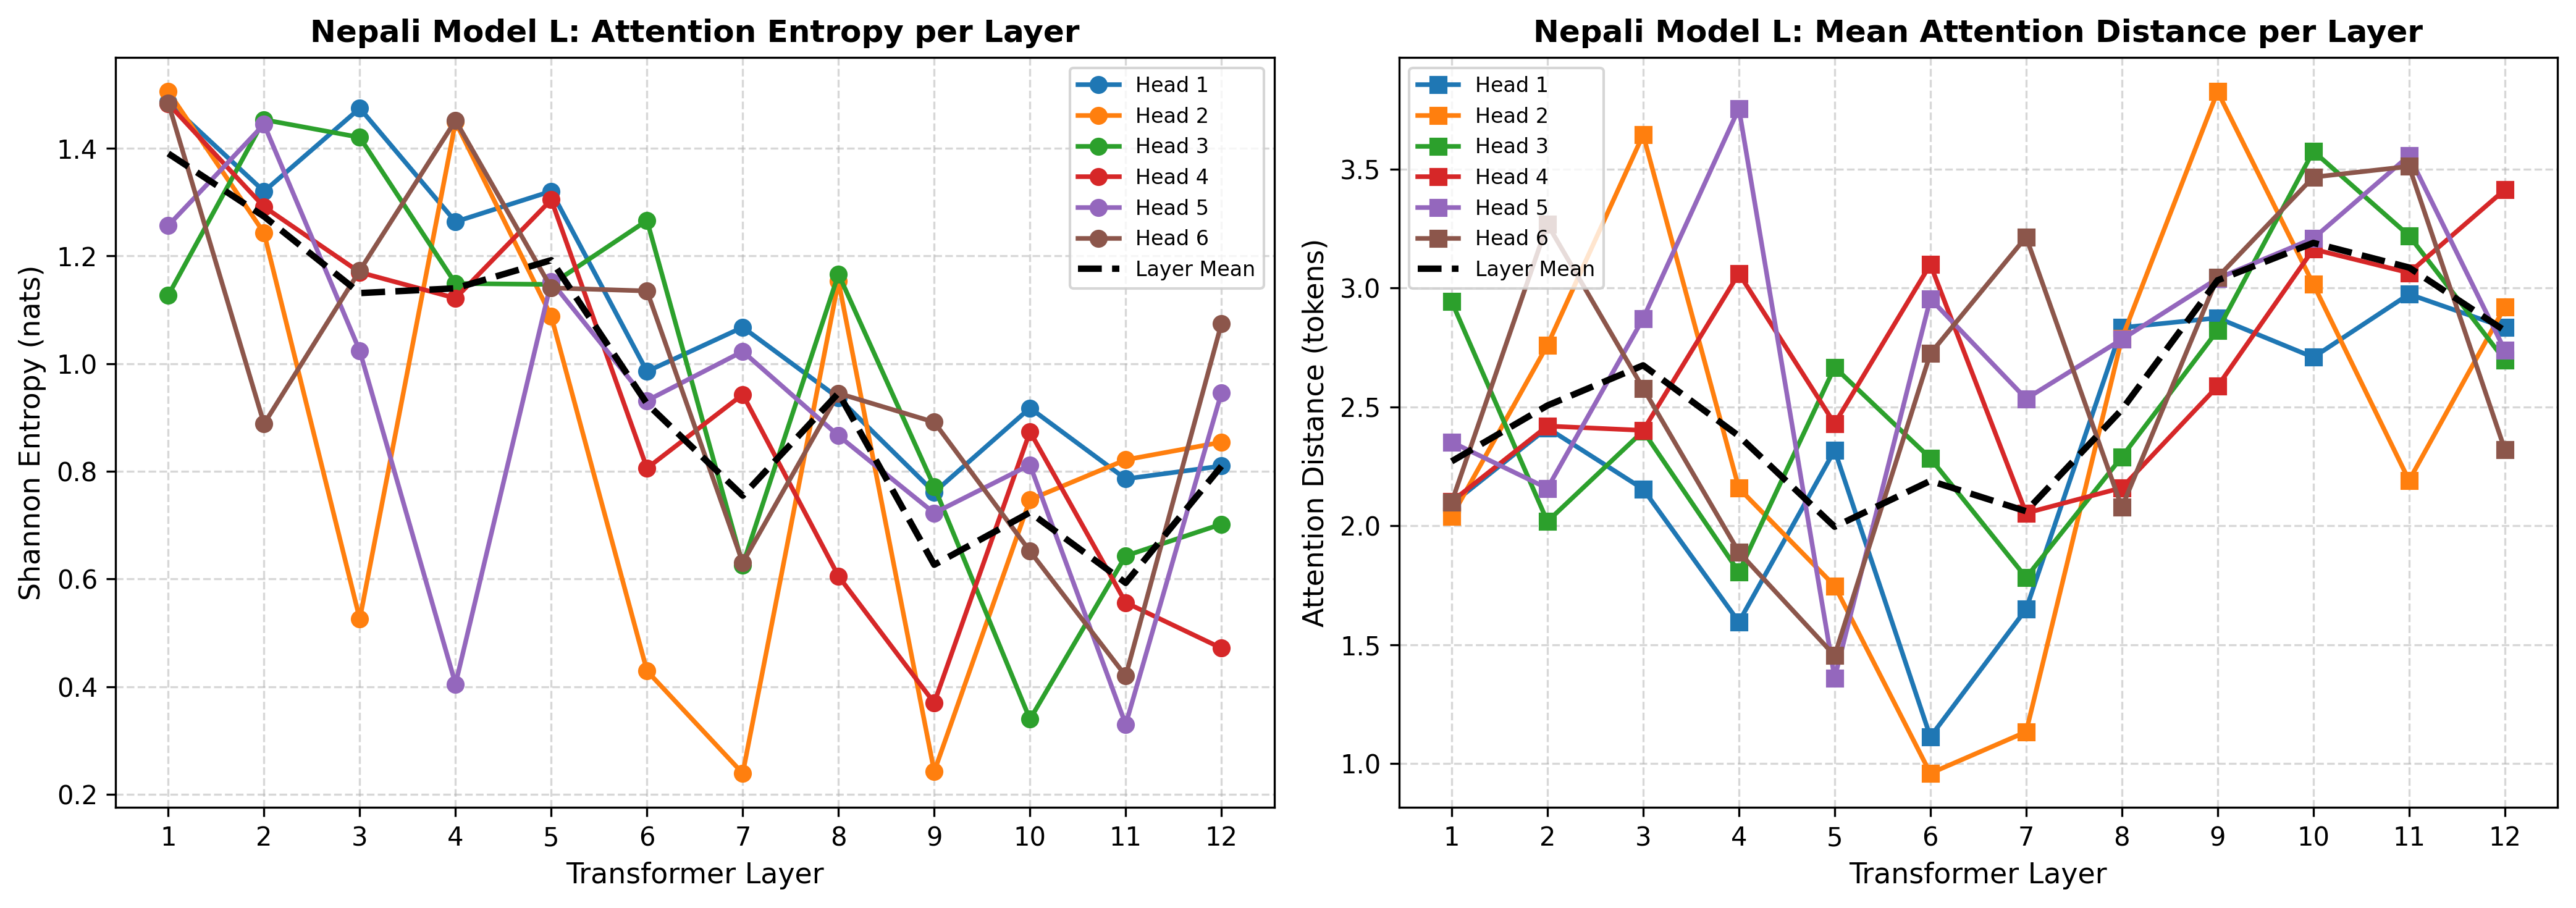

In [10]:
# CELL 8 — NEPALI ATTENTION ANALYSIS & READABLE HEATMAPS

#FORCE ASCII LABELS IN ATTENTION HEATMAPS

path = "/kaggle/working/nepali/eval/attention_analysis.py"

with open(path, "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if "xticklabels=clean_tokens" in line:
        lines[i] = '                xticklabels=[str(i) for i in range(len(clean_tokens))] if r_idx == num_layers - 1 else False,\n'

    if "yticklabels=clean_tokens" in line:
        lines[i] = '                yticklabels=[str(i) for i in range(len(clean_tokens))] if c_idx == 0 else False,\n'

with open(path, "w", encoding="utf-8") as f:
    f.writelines(lines)

print("Script patched successfully")

# Verify the actual lines
with open(path, "r", encoding="utf-8") as f:
    for i, line in enumerate(f, 1):
        if "xticklabels=" in line or "yticklabels=" in line:
            print(f"{i}: {line.strip()}")


# REGENERATE ATTENTION PLOTS

!rm -f nepali/eval/attention/nepali_attention_heatmaps.png

!python nepali/eval/attention_analysis.py \
    --checkpoint /kaggle/working/nepali_checkpoints/checkpoints/checkpoint_best.pt \
    --config_file nepali/configs/model_config.json \
    --tokenizer_model nepali/tokenizer/unigram_10k/tokenizer.model \
    --output_dir nepali/eval/attention \
    --sentence "नेपाली भाषा नेपालको राष्ट्रिय भाषा हो।"

# Display generated plots

from IPython.display import Image, display

display(Image("nepali/eval/attention/nepali_attention_heatmaps.png"))
display(Image("nepali/eval/attention/nepali_attention_entropy_distance.png"))

In [11]:
# CELL 9 — ZIP NEPALI TRAINING ARTIFACTS

import os

print("=" * 60)
print("ZIPPING NEPALI TRAINING ARTIFACTS")
print("=" * 60)

!zip -r /kaggle/working/nepali_checkpoints.zip \
    /kaggle/working/nepali_checkpoints/

zip_path = "/kaggle/working/nepali_checkpoints.zip"

print("\n ZIP created:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print(f"Size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")

print("\nFinal file:")
print(zip_path)

ZIPPING NEPALI TRAINING ARTIFACTS
  adding: kaggle/working/nepali_checkpoints/ (stored 0%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/ (stored 0%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_10000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_24000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_4000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_14000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_26000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_8000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_22000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/checkpoint_latest.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_18000.pt (deflated 12%)
  adding: kaggle/working/nepali_checkpoints/checkpoints/step_16000.pt 